In [166]:
# merchant_risk_score	Pontuação de risco associada ao estabelecimento comercial.
# prior_disputes	    Quantidade de contestações anteriores relacionadas ao cliente ou à sua atividade financeira. deve ser relacionado a idade do cartao (card_age_months)

In [167]:
# channel talvez possa ser reduzido a presencial ou online

In [168]:
# auth_method	Método de autenticação utilizado (senha, biometria, OTP etc.).
# sera que tem alguma classe que nao cai em fraude?

In [169]:
import pandas as pd
import numpy as np
import sklearn as skl
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report

In [170]:
FEATURES = ['proporcao_gasta_na_transacao']

In [171]:
df_test = pd.read_csv('data/test.csv')
df_train = pd.read_csv('data/train.csv')

In [172]:
def get_ids(df):
    return df['id']

In [173]:
def feature_engenier(df_1, df_2):
    df = pd.concat([df_1, df_2], axis=0).drop(columns='id')

    # Relação entre o valor da transação e o saldo disponivel: vou criar uma coluna que varia de 0.0 até 1.0
    # amount_usd / account_balance_usd
    df['proporcao_gasta_na_transacao'] = df['amount_usd'] / df['account_balance_usd']

    return df

In [174]:
df = feature_engenier(df_train, df_test)
df['merchant_risk_score'].mean()

fraudes = df.loc[df['is_fraud'] == 1, 'merchant_risk_score']
sem_fraudes = df.loc[df['is_fraud'] == 0, 'merchant_risk_score']

print('Fraudes:')
print('Média:', fraudes.mean())
print('Mediana:', fraudes.median())
print('Moda:', fraudes.mode()[0])

print('\nSem fraudes:')
print('Média:', sem_fraudes.mean())
print('Mediana:', sem_fraudes.median())
print('Moda:', sem_fraudes.mode()[0])

Fraudes:
Média: 47.368448969116265
Mediana: 45.9
Moda: 48.0

Sem fraudes:
Média: 35.01128918696269
Mediana: 34.0
Moda: 34.3


In [175]:
def transform_data(df) -> pd.DataFrame:
    TARGET = 'is_fraud'
    targets = df[TARGET].reset_index()
    df = df.drop(columns=[TARGET])

    boolean_features = list(df.select_dtypes(['bool']).columns)
    string_features = list(df.select_dtypes(['string', 'object']).columns)
    numeric_features = list(df.select_dtypes(['number']).drop(columns=FEATURES).columns)

    df[boolean_features] = df[boolean_features].astype(int)

    preprocess = ColumnTransformer(
        transformers= [
            ("num", StandardScaler(), numeric_features),
            ("str", OneHotEncoder(handle_unknown='ignore', sparse_output=False), string_features)
        ],
        remainder='passthrough'
    )

    df = preprocess.fit_transform(df)
    names = preprocess.get_feature_names_out()
    df = pd.DataFrame(data=df, columns=names).reset_index()

    df = pd.concat([df, targets['is_fraud']], axis=1)
    
    return df

In [176]:
ids = get_ids(df_test)
df = feature_engenier(df_train, df_test)
df = transform_data(df).drop(columns=['index'])
df

,num__amount_usd,num__hours_since_last_txn,num__txn_count_last_24h,num__distance_from_home_km,num__card_age_months,num__customer_age,num__account_balance_usd,num__cvv_retry_count,num__velocity_score,num__time_of_day_hour,...,str__device_type_Windows PC,str__device_type_iPhone,remainder__is_foreign_transaction,remainder__is_new_merchant,remainder__used_vpn,remainder__ip_country_mismatch,remainder__billing_shipping_mismatch,remainder__is_ai_generated_scam_attempt,remainder__proporcao_gasta_na_transacao,is_fraud
0,-0.091788,0.497909,-1.323864,0.360545,0.204879,0.255436,-0.233957,-0.295240,-1.236175,0.763141,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.048182,0.0
1,-0.269716,-0.809496,0.010672,-0.045816,-1.586508,-1.309079,0.342041,-0.295240,1.331491,1.636536,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007680,0.0
2,-0.360174,-0.863508,0.677940,-0.466813,0.563156,0.199561,-0.299215,-0.295240,1.552366,0.472009,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.006075,0.0
3,-0.207958,-0.239195,0.677940,-0.423766,0.204879,-0.191568,0.044214,-0.295240,0.162697,-0.692519,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.016883,0.0
4,2.810950,-0.927051,0.677940,-0.163764,-1.765646,0.031934,0.359072,-0.295240,1.460335,-1.129217,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.198675,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999939,-0.261292,-0.342452,-1.991132,-0.418601,-0.690814,0.534814,-0.460714,3.160255,-1.539877,0.472009,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.053495,NaN
999940,-0.351065,-0.628398,1.345209,-1.065163,-1.228230,-0.694448,0.190730,-0.295240,-0.067380,-1.129217,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.003025,NaN
999941,-0.172108,-0.361516,0.677940,1.885259,-0.511676,-1.364954,-0.079008,3.160255,1.064601,1.199839,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.024900,NaN
999942,-0.373643,-0.777725,0.010672,0.281339,-1.228230,-1.309079,0.417325,-0.295240,-0.720801,-1.274782,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.001034,NaN


In [177]:
df_train = df[:len(df_train)]
df_test = df[len(df_train):]
print(len(df_train), len(df_test))

699960 299984


In [178]:
x = df_train.drop(columns='is_fraud')
y = df_train['is_fraud']

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.3, shuffle=True, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, shuffle=True, random_state=42, stratify=y_temp)

print(x_train.shape, x_val.shape, x_test.shape)

(489972, 55) (104994, 55) (104994, 55)


In [179]:
skf = StratifiedKFold(n_splits=5)

results = []

for fold, (train_idx, val_idx) in enumerate(skf.split(x_train, y_train), start=1):
    x_tr, x_va = x_train.iloc[train_idx], x_train.iloc[val_idx]
    y_tr, y_va = y_train.iloc[train_idx], y_train.iloc[val_idx]
    
    xgb_cv = XGBClassifier()
    xgb_cv.fit(x_tr, y_tr,
               verbose = False)
    
    y_pred = xgb_cv.predict_proba(x_va)[:, 1]
    acc = roc_auc_score(y_va, y_pred)
    results.append(acc)
    print(f"Fold {fold}: roc_auc = {acc:.4f}")

Fold 1: roc_auc = 0.9304
Fold 2: roc_auc = 0.9288
Fold 3: roc_auc = 0.9374
Fold 4: roc_auc = 0.9339
Fold 5: roc_auc = 0.9301


In [180]:
params = {
    'n_estimators': 1000,
    'max_depth': 9,
    'eval_metric': 'auc',
    'learning_rate': 0.09918802139540925,
    'subsample': 0.6684329833808584,
    'colsample_bytree': 0.9151036654152414,
    'gamma': 0.14911870890152207,
    'reg_alpha': 0.10085071428350272,
    'reg_lambda': 0.6724424529145199,
    'min_child_weight': 2,
    'n_jobs': -1,
    'early_stopping_rounds': 10
}

xgb_clf = XGBClassifier(**params)
xgb_clf.fit(x_train, y_train, eval_set = [(x_val, y_val)])

[0]	validation_0-auc:0.89615
[1]	validation_0-auc:0.91639
[2]	validation_0-auc:0.92092
[3]	validation_0-auc:0.92558
[4]	validation_0-auc:0.92601
[5]	validation_0-auc:0.92773
[6]	validation_0-auc:0.92881
[7]	validation_0-auc:0.92906
[8]	validation_0-auc:0.92956
[9]	validation_0-auc:0.93082
[10]	validation_0-auc:0.93124
[11]	validation_0-auc:0.93177
[12]	validation_0-auc:0.93275
[13]	validation_0-auc:0.93328
[14]	validation_0-auc:0.93390
[15]	validation_0-auc:0.93441
[16]	validation_0-auc:0.93495
[17]	validation_0-auc:0.93525
[18]	validation_0-auc:0.93592
[19]	validation_0-auc:0.93624
[20]	validation_0-auc:0.93670
[21]	validation_0-auc:0.93696
[22]	validation_0-auc:0.93717
[23]	validation_0-auc:0.93719
[24]	validation_0-auc:0.93713
[25]	validation_0-auc:0.93767
[26]	validation_0-auc:0.93779
[27]	validation_0-auc:0.93789
[28]	validation_0-auc:0.93804
[29]	validation_0-auc:0.93821
[30]	validation_0-auc:0.93831
[31]	validation_0-auc:0.93825
[32]	validation_0-auc:0.93856
[33]	validation_0-au

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.9151036654152414
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",10
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


<Axes: >

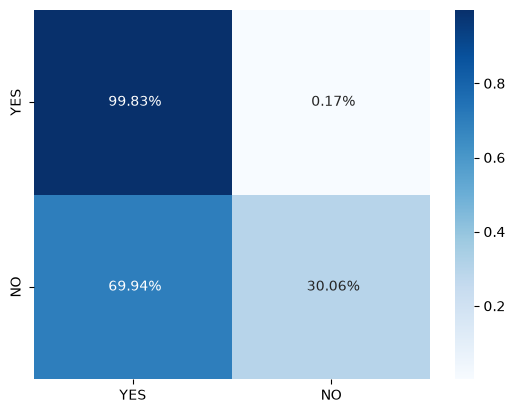

In [181]:
y_pred = xgb_clf.predict(x_test)
y_pred

cm = confusion_matrix(y_test, y_pred, normalize='true')

sns.heatmap(
    cm,
    cmap='Blues',
    fmt =" .2%",
    annot=True,
    xticklabels=["YES", "NO"],
    yticklabels=["YES", "NO"]
)

In [182]:
df_test = df_test.drop(columns=['is_fraud'])
out = xgb_clf.predict_proba(df_test)[:,1]
df_final = pd.DataFrame(
    {
        "id": ids,
        "is_fraud": out
    }
)

In [183]:
df_final.to_csv("solved_05.csv", index=False)

In [ ]:
# kaggle competitions submit -c playground-series-s6e11 -f solved_05.csv  -m "feature engenier"

UsageError: Line magic function `%kaggle` not found.


In [186]:
df_train

,num__amount_usd,num__hours_since_last_txn,num__txn_count_last_24h,num__distance_from_home_km,num__card_age_months,num__customer_age,num__account_balance_usd,num__cvv_retry_count,num__velocity_score,num__time_of_day_hour,...,str__device_type_Windows PC,str__device_type_iPhone,remainder__is_foreign_transaction,remainder__is_new_merchant,remainder__used_vpn,remainder__ip_country_mismatch,remainder__billing_shipping_mismatch,remainder__is_ai_generated_scam_attempt,remainder__proporcao_gasta_na_transacao,is_fraud
0,-0.091788,0.497909,-1.323864,0.360545,0.204879,0.255436,-0.233957,-0.295240,-1.236175,0.763141,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.048182,0.0
1,-0.269716,-0.809496,0.010672,-0.045816,-1.586508,-1.309079,0.342041,-0.295240,1.331491,1.636536,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007680,0.0
2,-0.360174,-0.863508,0.677940,-0.466813,0.563156,0.199561,-0.299215,-0.295240,1.552366,0.472009,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.006075,0.0
3,-0.207958,-0.239195,0.677940,-0.423766,0.204879,-0.191568,0.044214,-0.295240,0.162697,-0.692519,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.016883,0.0
4,2.810950,-0.927051,0.677940,-0.163764,-1.765646,0.031934,0.359072,-0.295240,1.460335,-1.129217,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.198675,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699955,3.112346,-0.402819,0.010672,-0.891254,-0.332537,-1.141452,-0.137408,-0.295240,0.171900,-1.565914,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.447538,0.0
699956,-0.233229,-1.047784,2.012477,-0.433237,-0.511676,1.652325,0.024212,3.160255,4.239672,-0.983651,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.015018,0.0
699957,-0.278924,-0.261435,0.677940,-0.806021,-1.765646,0.981818,-0.324734,-0.295240,0.033854,-1.129217,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.023909,0.0
699958,-0.321826,-0.758662,0.677940,1.247307,-1.228230,1.149445,-0.206531,-0.295240,1.110617,0.035311,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.010412,0.0
